# Clothing recognition — Step 1 setup
Select **Python (AML Fashion)**, then run the next cell. It imports dependencies and checks synthetic tensors only. No data is downloaded.
The official test set stays reserved for final evaluation. Dataset loading and a stratified training/validation split come next.

In [1]:
from pathlib import Path
import runpy
project_root = Path.cwd()
if not (project_root / "scripts/check_environment.py").exists():
    project_root = project_root.parent
check = project_root / "scripts/check_environment.py"
assert check.exists(), "Open Jupyter from the project folder"
status = runpy.run_path(str(check))["main"]()
assert status == 0, "Fix failed environment checks before continuing"

Python: 3.11.17 | Darwin arm64
Interpreter: /Users/krishnaverma/Desktop/AML_Project/fashion-classifier/.venv/bin/python
PASS import numpy: 1.26.4


PASS import pandas: 2.3.3
PASS import scipy: 1.17.1


PASS import torch: 2.14.1


PASS import torchvision: 0.29.1


PASS import sklearn: 1.9.1
PASS import skimage: 0.26.0
PASS import matplotlib: 3.11.2


/Users/krishnaverma/Desktop/AML_Project/fashion-classifier/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PASS import gradio: 6.30.0
PASS import PIL: 12.3.0


PASS import jupyterlab: 4.6.4
PASS import ipykernel: 7.4.0
PASS import nbformat: 5.11.1
PASS CPU matrix multiplication, gradients, torchvision NMS


PASS device operation: mps
ALL CHECKS PASSED. No dataset downloaded; no model trained.


# Step 2 — Load and inspect training data
We use only the **60,000 official training images**. The official test set is reserved for final evaluation.

**Stratified** means every clothing category keeps the same proportion in training and validation. We save the exact row indices so all future models use the same examples.

Source and archive checksums: [official Fashion-MNIST repository](https://github.com/zalandoresearch/fashion-mnist). Only the two training archives are downloaded; our loader avoids the TorchVision helper that also fetches test archives.

In [2]:
import sys
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.data import (CLASS_NAMES, load_training_data, load_or_create_split,
                      scale_pixels, save_preprocessing_config)

images, labels = load_training_data(project_root, download=True)
print('Images:', images.shape, images.dtype)
print('Labels:', labels.shape, labels.dtype)
print('Raw pixel range:', int(images.min()), 'to', int(images.max()))
assert images.shape == (60000, 28, 28)
assert images.dtype == np.uint8
assert (images.min(), images.max()) == (0, 255)

Matplotlib is building the font cache; this may take a moment.


Images: (60000, 28, 28) uint8
Labels: (60000,) uint8
Raw pixel range: 0 to 255


## Save the shared split
Seed **42** makes the split repeatable: **48,000 training** and **12,000 validation** images. The saved file is checked and reused on subsequent runs. Indices identify rows in the original training arrays, not copies of the pictures.

In [3]:
train_indices, validation_indices = load_or_create_split(labels, project_root)
config = save_preprocessing_config(project_root)
counts = pd.DataFrame({
    'label': np.arange(10), 'category': CLASS_NAMES,
    'official_training': np.bincount(labels, minlength=10),
    'training': np.bincount(labels[train_indices], minlength=10),
    'validation': np.bincount(labels[validation_indices], minlength=10),
})
print('Training:', len(train_indices), '| Validation:', len(validation_indices))
print('Overlap:', np.intersect1d(train_indices, validation_indices).size)
counts.to_csv(project_root / 'reports/class_counts.csv', index=False)
display(counts)

Training: 48000 | Validation: 12000
Overlap: 0


,label,category,official_training,training,validation
0,0,T-shirt/top,6000,4800,1200
1,1,Trouser,6000,4800,1200
2,2,Pullover,6000,4800,1200
3,3,Dress,6000,4800,1200
4,4,Coat,6000,4800,1200
5,5,Sandal,6000,4800,1200
6,6,Shirt,6000,4800,1200
7,7,Sneaker,6000,4800,1200
8,8,Bag,6000,4800,1200
9,9,Ankle boot,6000,4800,1200


## Inspect representative training images
Three examples from each class, selected **only from the 48,000-image training split**, with a fixed seed. Displayed in their original orientation: grayscale clothing on a dark background. Similar shapes among shirts, T-shirts/tops, pullovers, and coats may cause confusion later.

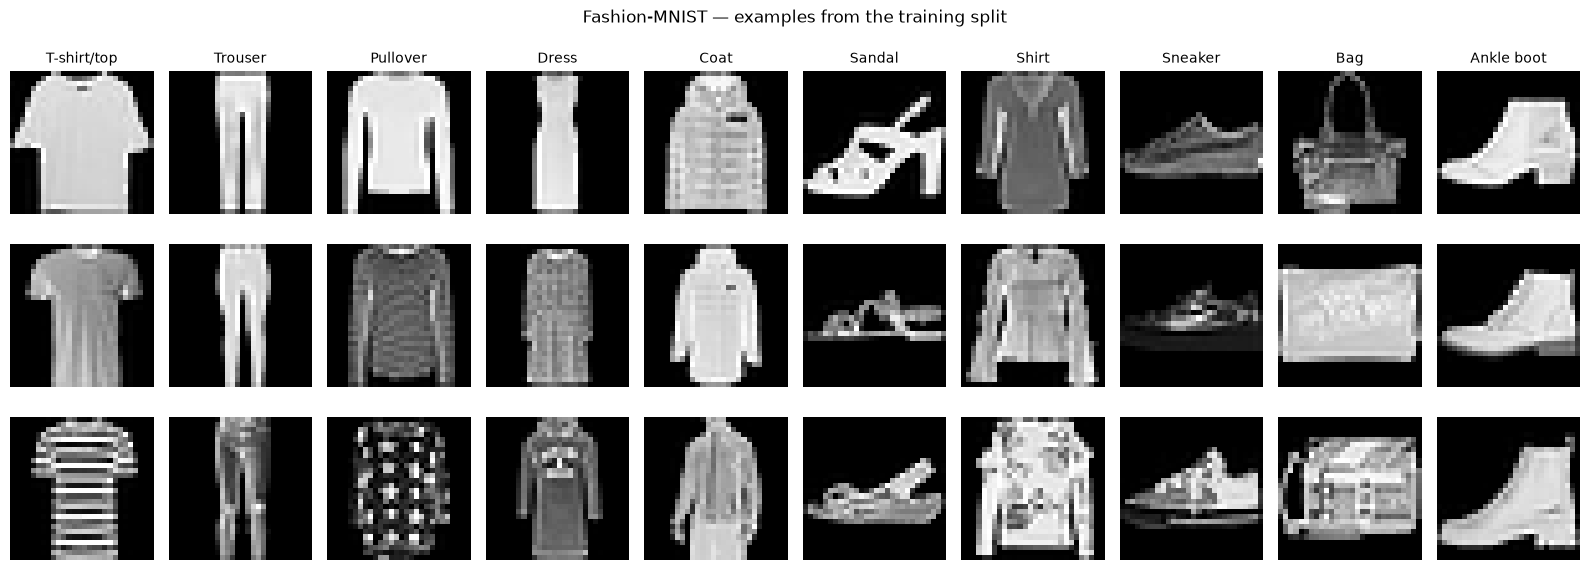

In [4]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(3, 10, figsize=(16, 6))
for label, name in enumerate(CLASS_NAMES):
    candidates = train_indices[labels[train_indices] == label]
    for row, index in enumerate(rng.choice(candidates, 3, replace=False)):
        ax = axes[row, label]
        ax.imshow(images[index], cmap='gray', vmin=0, vmax=255)
        ax.axis('off')
        if row == 0:
            ax.set_title(name, fontsize=10)
fig.suptitle('Fashion-MNIST — examples from the training split')
fig.tight_layout()
(project_root / 'reports/figures').mkdir(parents=True, exist_ok=True)
fig.savefig(project_root / 'reports/figures/training_examples.png', dpi=150, bbox_inches='tight')
plt.show()

## Scale pixels consistently
Dividing by **255** maps raw pixel values from **0–255** to **0–1** as `float32`. This fixed rule learns nothing from the data. Future learned transformations (for example, a standard scaler) must be fitted on training examples only.

The two-dimensional image layout is retained. Later, classical models can flatten it to 784 features, while the CNN can add a channel dimension to get `(N, 1, 28, 28)`.

In [5]:
X_train = scale_pixels(images[train_indices])
X_validation = scale_pixels(images[validation_indices])
y_train = labels[train_indices]
y_validation = labels[validation_indices]
for name, array in [('Training', X_train), ('Validation', X_validation)]:
    print(name, array.shape, array.dtype, 'range:', float(array.min()), float(array.max()))
    assert array.dtype == np.float32
    assert 0 <= array.min() <= array.max() <= 1
assert np.array_equal(y_train, labels[train_indices])
assert np.array_equal(y_validation, labels[validation_indices])

Training (48000, 28, 28) float32 range: 0.0 1.0
Validation (12000, 28, 28) float32 range: 0.0 1.0


## Verification and saved progress
Check that reloading preserves the split and that no official test files were downloaded. No model is trained in this milestone.

Saved artifacts: `data/processed/train_validation_split.npz`, `data/processed/preprocessing.json`, `reports/class_counts.csv`, `reports/figures/training_examples.png`, and `reports/step2-summary.json`.

Next milestone: flattened-pixel and HOG baselines, using these same indices.

In [6]:
again_train, again_validation = load_or_create_split(labels, project_root)
assert np.array_equal(train_indices, again_train)
assert np.array_equal(validation_indices, again_validation)
test_files = [str(p.relative_to(project_root)) for p in (project_root / 'data').rglob('*')
              if p.is_file() and ('t10k' in p.name or 'fashion-mnist_test' in p.name)]
assert not test_files, f'Unexpected test files present: {test_files}'
summary = {
    'milestone': 2, 'status': 'complete',
    'official_training_images': len(images), 'image_shape': list(images.shape[1:]),
    'raw_pixel_range': [int(images.min()), int(images.max())],
    'train_size': len(train_indices), 'validation_size': len(validation_indices),
    'seed': 42, 'stratified': True, 'overlap': 0,
    'split_reload_identical': True, 'official_test_files_present': test_files,
    'labels_sha256': hashlib.sha256(labels.tobytes()).hexdigest(),
    'python': platform.python_version(), 'numpy': np.__version__,
    'scikit_learn': sklearn.__version__, 'models_trained': 0,
}
(project_root / 'reports/step2-summary.json').write_text(json.dumps(summary, indent=2) + '\n')
print('Step 2 checks passed. Split saved and reused. Official test set untouched. No models trained.')

Step 2 checks passed. Split saved and reused. Official test set untouched. No models trained.


# Step 3 — Traditional machine-learning baselines
We compare four classifiers with two representations, giving **eight model/feature combinations**:

| Representation | What the model sees |
|---|---|
| Flattened pixels | The 28×28 image as 784 brightness values, scaled to 0–1 |
| HOG | 324 values describing local edge directions and shapes |

HOG settings: 9 orientation bins, 7×7 pixels per cell, 2×2 cells per block, L2-Hys normalization. Images keep their original orientation. HOG is a fixed descriptor; it does not learn from validation data.

**Compute budget:** every model uses the same saved, stratified **12,000-example subset** drawn only from the 48,000 training indices (seed 42; 1,200 per class). All models are evaluated on all 12,000 validation indices. The remaining training examples are unused in this initial budgeted comparison. These scores must not be described as full-training-set results.

**Selection:** two predeclared settings per model, for each representation; 16 candidate fits. Select the highest validation macro F1, with accuracy as a tie breaker. Macro F1 gives equal importance to each clothing class. Validation scores guide selection and may be optimistic; official test data remains reserved.

| Classifier | Candidate settings |
|---|---|
| Logistic Regression | C = 0.1, 1; max_iter = 1,000; lbfgs |
| kNN | k = 3, 5; distance weighting; Euclidean distance |
| Random Forest | 100 trees; maximum depth = 20 or unlimited; sqrt feature sampling |
| Linear SVM | C = 0.1, 1; max_iter = 10,000; dual = auto |

Logistic Regression and linear SVM use StandardScaler fitted **only on the 12,000 training examples**, saved inside each model pipeline. kNN and Random Forest use the fixed pixel/HOG values directly. Convergence warnings exclude a candidate from selection. We use two CPU threads to keep resource use modest.

A linear SVM is chosen for this first practical run. A nonlinear RBF SVM is outside the current compute budget.

In [1]:
from pathlib import Path
import sys
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / 'src/data.py').exists():
    project_root = project_root.parent
assert (project_root / 'src/data.py').exists(), 'Open this notebook from the project or notebooks folder'
report_dir = project_root / 'reports/baselines'
# Reuse completed results; avoid retraining on every Run All.
if not (report_dir / 'summary.json').exists():
    subprocess.run([sys.executable, '-m', 'src.baselines'], cwd=project_root, check=True)
summary = json.loads((report_dir / 'summary.json').read_text())
results = pd.read_csv(report_dir / 'validation_results.csv')
print('Selected model per feature/classifier combination — validation scores only')
display(results[['features', 'model', 'training_images', 'feature_count', 'parameters',
                 'accuracy', 'macro_f1', 'fit_seconds', 'saved_model_bytes']])

Selected model per feature/classifier combination — validation scores only


,features,model,training_images,feature_count,parameters,accuracy,macro_f1,fit_seconds,saved_model_bytes
0,pixels,random_forest,12000,784,"{""max_depth"": null, ""max_features"": ""sqrt"", ""n...",0.864583,0.862814,3.495747,5525862
1,hog,logistic_regression,12000,324,"{""C"": 0.1, ""max_iter"": 1000, ""solver"": ""lbfgs""}",0.839417,0.839137,1.255761,20699
2,hog,linear_svm,12000,324,"{""C"": 0.1, ""dual"": ""auto"", ""max_iter"": 10000}",0.840333,0.839120,6.174628,33306
3,pixels,logistic_regression,12000,784,"{""C"": 0.1, ""max_iter"": 1000, ""solver"": ""lbfgs""}",0.837500,0.837426,6.345722,48052
4,pixels,knn,12000,784,"{""metric"": ""euclidean"", ""n_neighbors"": 5, ""wei...",0.834667,0.834612,0.005004,8157660
5,hog,random_forest,12000,324,"{""max_depth"": 20, ""max_features"": ""sqrt"", ""n_e...",0.828417,0.827967,4.042523,6429220
6,hog,knn,12000,324,"{""metric"": ""euclidean"", ""n_neighbors"": 5, ""wei...",0.822417,0.822454,0.001491,10004959
7,pixels,linear_svm,12000,784,"{""C"": 0.1, ""dual"": ""auto"", ""max_iter"": 10000}",0.819250,0.817884,162.803619,79018


## Compare validation performance
Each bar shows the best of the two candidates for that classifier and representation. Accuracy is the fraction of correct predictions. Macro F1 averages a precision/recall balance across the ten classes.

Training and prediction times are preliminary local CPU measurements. Prediction times include any pipeline scaler but exclude pixel/HOG extraction; a consistent end-to-end inference benchmark comes in Step 5. Compressed model file sizes are storage measurements, not equivalent parameter counts.

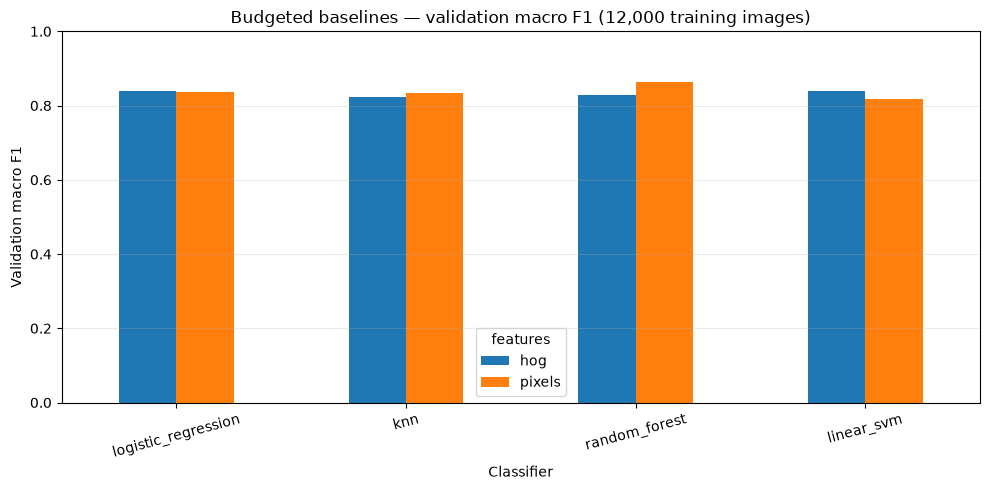

Highest validation macro F1: pixels/random_forest
Accuracy: 0.8646
Macro F1: 0.8628
These are selection results, not official test scores.


In [2]:
comparison = results.pivot(index='model', columns='features', values='macro_f1')
comparison = comparison.reindex(['logistic_regression', 'knn', 'random_forest', 'linear_svm'])
ax = comparison.plot.bar(figsize=(10, 5), ylim=(0, 1), rot=15)
ax.set_title('Budgeted baselines — validation macro F1 (12,000 training images)')
ax.set_xlabel('Classifier')
ax.set_ylabel('Validation macro F1')
ax.grid(axis='y', alpha=0.25)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(project_root / 'reports/figures/baseline_validation_macro_f1.png', dpi=150)
plt.show()
print('Highest validation macro F1:', summary['best_validation_model'])
print('Accuracy:', round(summary['best_validation_accuracy'], 4))
print('Macro F1:', round(summary['best_validation_macro_f1'], 4))
print('These are selection results, not official test scores.')

## Verify saved outputs
Saved: the shared baseline training subset; all 16 candidate results; eight selected fitted models including learned preprocessing; eight validation prediction arrays; per-class recall; settings and version metadata.

The checks below reload each model and verify its predictions for a small validation batch. They also confirm the original Step 2 split is unchanged and the official test files are absent.

**Next milestone:** Step 4, a small CNN with validation monitoring, early stopping, and a best-validation checkpoint. Before the final comparison, document or align training-data budgets; a full 48,000-image CNN and these 12,000-image baselines would have different training budgets.

In [3]:
import hashlib
import joblib
from sklearn.metrics import accuracy_score, f1_score
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.data import load_training_data, load_or_create_split
from src.baselines import features

images, labels = load_training_data(project_root, download=False)
train_indices, validation_indices = load_or_create_split(labels, project_root)
subset = np.load(project_root / 'data/processed/baseline_train_indices.npy', allow_pickle=False)
assert len(subset) == 12000 and len(np.unique(subset)) == 12000
assert np.isin(subset, train_indices).all()
assert not np.intersect1d(subset, validation_indices).size
assert np.all(np.bincount(labels[subset], minlength=10) == 1200)
assert hashlib.sha256((project_root / 'data/processed/train_validation_split.npz').read_bytes()).hexdigest() == summary['split_sha256']
all_candidates = pd.read_csv(report_dir / 'candidates.csv')
assert len(all_candidates) == 16 and len(results) == 8
with np.load(report_dir / 'validation_predictions.npz', allow_pickle=False) as saved:
    assert np.array_equal(saved['validation_indices'], validation_indices)
    assert np.array_equal(saved['true_labels'], labels[validation_indices])
    for row in results.itertuples():
        key = f'{row.features}_{row.model}'
        pred = saved[key]
        assert np.isclose(accuracy_score(saved['true_labels'], pred), row.accuracy)
        assert np.isclose(f1_score(saved['true_labels'], pred, average='macro'), row.macro_f1)
        fitted = joblib.load(project_root / f'models/baselines/{key}.joblib')
        batch = features(images[validation_indices[:20]], row.features)
        assert np.array_equal(fitted.predict(batch), pred[:20])
        assert np.array_equal(fitted.classes_, np.arange(10))
assert not [p for p in (project_root / 'data').rglob('*') if p.is_file() and ('t10k' in p.name or 'fashion-mnist_test' in p.name)]
print('Verified all eight saved models, validation metrics, subset membership, and unchanged shared split.')
print('Official test data remains untouched.')

Verified all eight saved models, validation metrics, subset membership, and unchanged shared split.
Official test data remains untouched.


# Step 4 — A small CNN with early stopping
A **convolutional neural network (CNN)** learns local image patterns from examples. Unlike flattened pixels, convolution preserves spatial neighborhoods; unlike HOG, the filters are learned during training.

This model adapts the original reference's two-block design:

`1×28×28 → Conv(32) + BatchNorm + ReLU + Pool → 32×14×14 → Conv(64) + BatchNorm + ReLU + Pool → 64×7×7 → Flatten → 128 → 64 → 10 logits`

The classifier uses dropout of **0.4** after each hidden layer. Cross-entropy receives raw logits; softmax is used only when exporting class probabilities. BatchNorm learns from training batches and uses its stored running statistics during validation.

**Matched data budget:** exactly the same saved **12,000 training indices** and **12,000 validation indices** as all Step 3 baselines. The full shared training split contains 48,000 images, but the unused 36,000 are excluded from this first matched comparison. No augmentation, orientation changes, or test examples are used.

| Setting | Value |
|---|---|
| Input | float32, `(N,1,28,28)`, pixels divided by 255 |
| Optimizer | Adam; learning rate 0.001; weight decay 0.0001 |
| Batch size | 128 |
| Maximum epochs | 25 |
| Early stopping | 5 consecutive epochs without a lower validation loss |
| Checkpoint selection | Minimum validation cross-entropy loss, not last epoch |
| Seed | 42; one seeded run; exact cross-device/version reproducibility is not guaranteed |
| Device | MPS when available, otherwise CPU |

**Early stopping** means checking validation loss after each epoch and stopping when it no longer improves for five epochs. Whenever it improves, the model weights and BatchNorm buffers are saved. We restore that best checkpoint before reporting validation scores.

In [1]:
from pathlib import Path
import sys
import json
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

project_root = Path.cwd()
if not (project_root / 'src/model.py').exists():
    project_root = project_root.parent
assert (project_root / 'src/model.py').exists()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.model import SmallCNN, count_parameters

cnn_report = project_root / 'reports/cnn'
# Completed runs are reused. Training also refuses to overwrite an existing checkpoint.
if not (cnn_report / 'summary.json').exists():
    subprocess.run([sys.executable, '-m', 'src.train'], cwd=project_root, check=True)
cnn_summary = json.loads((cnn_report / 'summary.json').read_text())
history = pd.read_csv(cnn_report / 'history.csv')
print('Training device:', cnn_summary['device'])
print('Trainable parameters:', f"{cnn_summary['trainable_parameters']:,}")
print('Epochs run:', cnn_summary['epochs_run'], '| Best epoch:', cnn_summary['best_epoch'])
print('Early stopping triggered:', cnn_summary['early_stopped'])
print('Restored-checkpoint validation accuracy:', round(cnn_summary['validation_accuracy'], 4))
print('Restored-checkpoint validation macro F1:', round(cnn_summary['validation_macro_f1'], 4))
print(SmallCNN())
display(history)

Training device: mps
Trainable parameters: 429,450
Epochs run: 14 | Best epoch: 9
Early stopping triggered: True
Restored-checkpoint validation accuracy: 0.8992
Restored-checkpoint validation macro F1: 0.898
SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,seconds,checkpoint_saved
0,1,0.962548,0.659250,0.490316,0.826667,0.824679,4.905519,True
1,2,0.563577,0.799667,0.389517,0.855833,0.851098,1.056290,True
2,3,0.472832,0.831167,0.361537,0.869583,0.865767,1.103662,True
3,4,0.420221,0.849000,0.329559,0.884167,0.883328,1.088125,True
4,5,0.383480,0.863667,0.319085,0.884750,0.881260,1.091681,True
5,6,0.350991,0.875833,0.352295,0.872083,0.870954,1.086042,False
6,7,0.324980,0.886833,0.295148,0.895333,0.894982,1.101329,True
7,8,0.302987,0.895167,0.294021,0.895167,0.893075,1.081270,True
8,9,0.281621,0.899083,0.284813,0.899250,0.898020,1.086955,True
9,10,0.268429,0.900000,0.289362,0.897250,0.895099,1.120693,False


## Learning curves
Training loss/accuracy are accumulated while the model learns, with dropout enabled. Validation uses evaluation mode with dropout disabled and frozen BatchNorm statistics. Their curves therefore come from different modes; validation accuracy can exceed training accuracy.

The dashed line marks the saved best-loss epoch. All curves below use only training and validation data. If the maximum epoch count is reached first, early stopping remains implemented but is reported as not triggered.

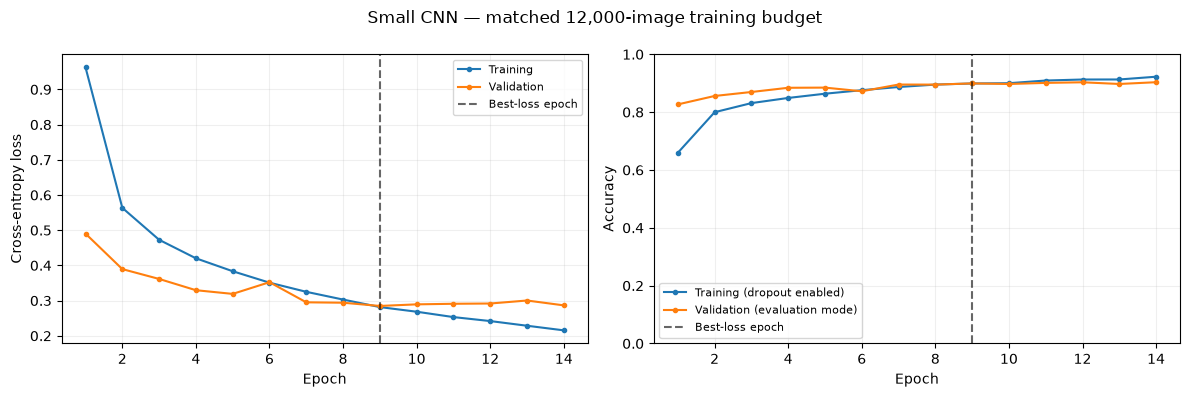

,model,training_images,validation_accuracy,validation_macro_f1
0,pixels/random_forest,12000,0.864583,0.862814
1,small CNN (best validation-loss checkpoint),12000,0.899250,0.898020


Matched training examples; different optimization/search budgets and selection criteria.
Validation selection results only — official test evaluation belongs to Step 5.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, label in [('train_loss', 'Training'), ('validation_loss', 'Validation')]:
    axes[0].plot(history.epoch, history[column], marker='.', label=label)
for column, label in [('train_accuracy', 'Training (dropout enabled)'), ('validation_accuracy', 'Validation (evaluation mode)')]:
    axes[1].plot(history.epoch, history[column], marker='.', label=label)
axes[0].set_ylabel('Cross-entropy loss')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.axvline(cnn_summary['best_epoch'], color='black', linestyle='--', alpha=0.6, label='Best-loss epoch')
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle('Small CNN — matched 12,000-image training budget')
fig.tight_layout()
fig.savefig(project_root / 'reports/figures/cnn_learning_curves.png', dpi=150)
plt.show()

baseline = pd.read_csv(project_root / 'reports/baselines/validation_results.csv').iloc[0]
comparison = pd.DataFrame([
    {'model': f"{baseline['features']}/{baseline['model']}", 'training_images': int(baseline['training_images']),
     'validation_accuracy': baseline['accuracy'], 'validation_macro_f1': baseline['macro_f1']},
    {'model': 'small CNN (best validation-loss checkpoint)', 'training_images': cnn_summary['training_images'],
     'validation_accuracy': cnn_summary['validation_accuracy'], 'validation_macro_f1': cnn_summary['validation_macro_f1']},
])
comparison.to_csv(cnn_report / 'vs_baseline_validation.csv', index=False)
display(comparison)
print('Matched training examples; different optimization/search budgets and selection criteria.')
print('Validation selection results only — official test evaluation belongs to Step 5.')

## Reload and verify the saved checkpoint
`models/cnn/best.pt` stores portable CPU tensors plus architecture, preprocessing, class names, split fingerprints, and training settings. `models/cnn/config.json` is a readable copy of the configuration. Optimizer state is not saved; this checkpoint is for best-model inference, not exact training resumption.

The checks below load it on CPU, confirm the architecture and class order, compare a validation batch with saved MPS/CPU probabilities within numerical tolerance, and recompute saved validation metrics. Training already verified that restoring the checkpoint reproduces its best validation loss.

Other outputs: `reports/cnn/history.csv`, `summary.json`, `validation_predictions.npz`, `per_class_recall.csv`, `architecture.txt`, and `reports/step4-execution.log`.

Next milestone: freeze model choices, then conduct the final official-test comparison and error analysis. The current results use one seed and a matched subset; they do not establish performance on real clothing photographs.

In [3]:
import hashlib
from sklearn.metrics import accuracy_score, f1_score
from src.data import CLASS_NAMES, load_training_data, load_or_create_split, scale_pixels

torch.set_num_threads(2)
checkpoint = torch.load(project_root / 'models/cnn/best.pt', map_location='cpu', weights_only=True)
reloaded = SmallCNN()
reloaded.load_state_dict(checkpoint['state_dict'])
reloaded.eval()
assert count_parameters(reloaded) == cnn_summary['trainable_parameters']
assert checkpoint['class_names'] == list(CLASS_NAMES)
assert checkpoint['epoch'] == int(history.loc[history.validation_loss.idxmin(), 'epoch'])
images, labels = load_training_data(project_root, download=False)
train_idx, val_idx = load_or_create_split(labels, project_root)
subset = np.load(project_root / 'data/processed/baseline_train_indices.npy', allow_pickle=False)
assert hashlib.sha256(subset.tobytes()).hexdigest() == cnn_summary['subset_sha256']
assert np.isin(subset, train_idx).all() and not np.intersect1d(subset, val_idx).size
assert len(subset) == cnn_summary['training_images'] == 12000
with np.load(cnn_report / 'validation_predictions.npz', allow_pickle=False) as saved:
    assert np.array_equal(saved['validation_indices'], val_idx)
    assert np.array_equal(saved['true_labels'], labels[val_idx])
    assert np.isclose(accuracy_score(saved['true_labels'], saved['predictions']), cnn_summary['validation_accuracy'])
    assert np.isclose(f1_score(saved['true_labels'], saved['predictions'], average='macro'), cnn_summary['validation_macro_f1'])
    batch = torch.from_numpy(scale_pixels(images[val_idx[:64]])[:, None, :, :])
    with torch.inference_mode():
        cpu_probabilities = reloaded(batch).softmax(1).numpy()
    assert np.allclose(cpu_probabilities, saved['probabilities'][:64], rtol=0.002, atol=0.0002)
    assert np.array_equal(cpu_probabilities.argmax(1), saved['predictions'][:64])
protected = json.loads((project_root / 'reports/step3-backup/protected-sha256.json').read_text())
for relative, digest in protected.items():
    assert hashlib.sha256((project_root / relative).read_bytes()).hexdigest() == digest, relative
assert not [p for p in (project_root / 'data').rglob('*') if p.is_file() and ('t10k' in p.name or 'fashion-mnist_test' in p.name)]
print('Verified portable checkpoint reload, validation predictions/metrics, matched training subset, and unchanged reference/splits/baseline models.')
print('Official test files remain absent.')

Verified portable checkpoint reload, validation predictions/metrics, matched training subset, and unchanged reference/splits/baseline models.
Official test files remain absent.
